## Preparing the GPS Data for Analysis

In [9]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import matplotlib as mpl
import pandas as pd

### 1 SSC Measurement Campaign

For this campaign, the following data points and transects in the dataset are identified±
1. TESTXXXXXX: continuous measurements of the boat trajectory during the experiment
2. PERFJAGXXXXXX: continuous measurement of the transect between the shore and the measurement equipment
3. GPSXXXXXX: discrete measurements of the position of the measurement equipment and auxiliary materials
    - GPS000001 is the west flagpole
    - GPS000002 is the measurement pyramid
    - GPS000003 is the east flagpole
    - GPS000004 is the cooperating flagpole
    - GPS000005 is the beach

In [31]:
file_path = r"Pruebas_DELFT_20260929.txt"
# Use the 20260926 filename here if that is the actual file you have.

columns = [
    "point_id",
    "date",
    "time",
    "easting",
    "northing",
    "ellipsoidal_height",
    "geoid_separation",
    "cq_3d",
]

gps = pd.read_csv(
    file_path,
    sep=r"\s+",
    skiprows=1,          # skip the descriptive header
    names=columns,
    dtype={
        "point_id": "string",
        "date": "string",
        "time": "string",
        "easting": "float64",
        "northing": "float64",
        "ellipsoidal_height": "float64",
        "geoid_separation": "float64",
        "cq_3d": "float64",
    },
)

gps["datetime"] = pd.to_datetime(
    gps["date"] + " " + gps["time"],
    format="%m/%d/%Y %H:%M:%S",
)
gps["datetime"] = gps["datetime"] - pd.Timedelta(hours=1)

gps = gps.drop(columns=["date", "time"])

display(gps.head())
print(gps.dtypes)

,point_id,easting,northing,ellipsoidal_height,geoid_separation,cq_3d,datetime
0,GPS0001,806688.1680,2.343461e+06,-15.2602,-13.9310,0.0159,2026-09-29 11:18:19
1,GPS0002,806687.4266,2.343459e+06,-15.2558,-13.9309,0.0159,2026-09-29 11:18:40
2,GPS0003,806697.2479,2.343461e+06,-15.3033,-13.9310,0.0177,2026-09-29 11:19:18
3,GPS0004,806687.4149,2.343452e+06,-15.3480,-13.9308,0.0156,2026-09-29 11:19:56
4,GPS0005,806680.4073,2.343383e+06,-14.3263,-13.9294,0.0210,2026-09-29 11:22:42


point_id              string[python]
easting                      float64
northing                     float64
ellipsoidal_height           float64
geoid_separation             float64
cq_3d                        float64
datetime              datetime64[ns]
dtype: object


,point_id,trajectory,datetime,speed_m_s,speed_km_h
0,GPS0001,GPS,2026-09-29 11:18:19,NaN,NaN
1,GPS0002,GPS,2026-09-29 11:18:40,0.074992,0.269972
2,GPS0003,GPS,2026-09-29 11:19:18,0.264426,0.951933
3,GPS0004,GPS,2026-09-29 11:19:56,0.362235,1.304045
4,GPS0005,GPS,2026-09-29 11:22:42,0.417235,1.502046


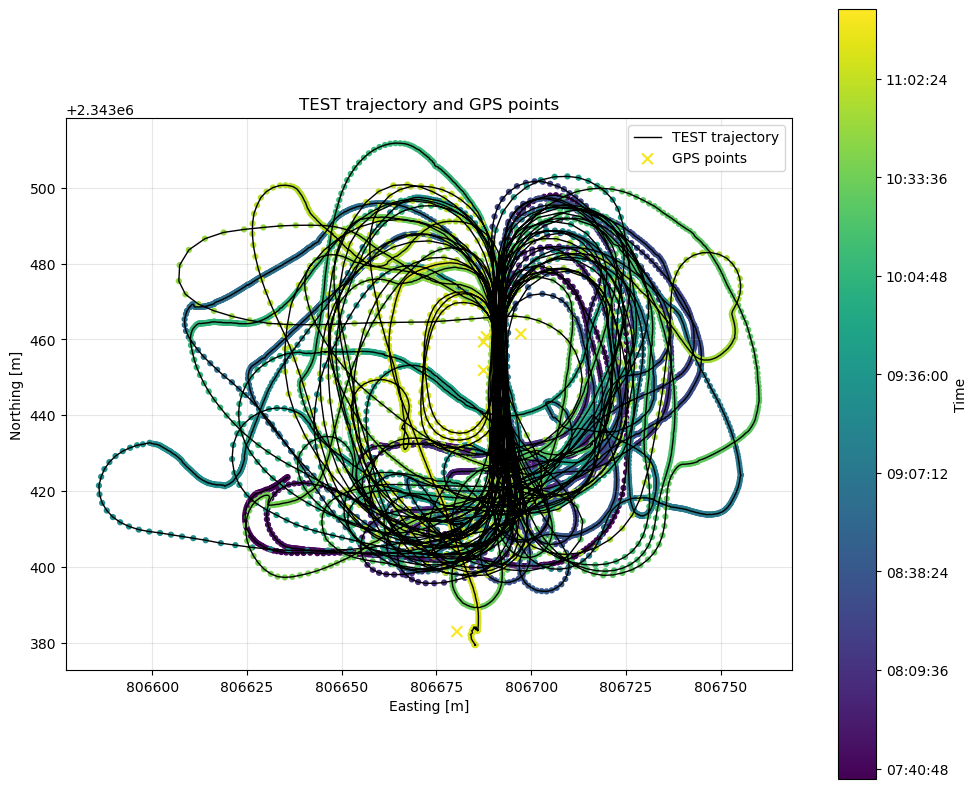

In [32]:
# Extract the label from point_id
gps["trajectory"] = gps["point_id"].str.extract(
    r"^([A-Za-z]+)",
    expand=False,
)

test = gps[gps["trajectory"] == "TEST"].sort_values("datetime")
gps_points = gps[gps["trajectory"] == "GPS"].sort_values("datetime")

# Calculate horizontal speed within each trajectory
ordered_gps = gps.sort_values(["trajectory", "datetime"])

delta_easting = ordered_gps.groupby("trajectory")["easting"].diff()
delta_northing = ordered_gps.groupby("trajectory")["northing"].diff()

delta_time = (
    ordered_gps.groupby("trajectory")["datetime"]
    .diff()
    .dt.total_seconds()
)

distance = np.hypot(delta_easting, delta_northing)

# Speed in metres per second
speed_m_s = distance / delta_time.where(delta_time > 0)

# Add the results to the original DataFrame order
gps["speed_m_s"] = speed_m_s.reindex(gps.index)
gps["speed_km_h"] = gps["speed_m_s"] * 3.6

display(
    gps[
        [
            "point_id",
            "trajectory",
            "datetime",
            "speed_m_s",
            "speed_km_h",
        ]
    ].head()
)

# Use one colour scale for both datasets
plot_data = pd.concat([test, gps_points])
time_values = mdates.date2num(plot_data["datetime"])

norm = mpl.colors.Normalize(
    time_values.min(),
    time_values.max(),
)
cmap = plt.colormaps["viridis"]

fig, ax = plt.subplots(figsize=(10, 8))

# TEST: chronological connected trajectory
ax.plot(
    test["easting"],
    test["northing"],
    color="black",
    linewidth=1,
    label="TEST trajectory",
)

ax.scatter(
    test["easting"],
    test["northing"],
    c=mdates.date2num(test["datetime"]),
    cmap=cmap,
    norm=norm,
    s=12,
)

# GPS: discrete points, not connected
ax.scatter(
    gps_points["easting"],
    gps_points["northing"],
    c=mdates.date2num(gps_points["datetime"]),
    cmap=cmap,
    norm=norm,
    marker="x",
    s=60,
    linewidths=1.5,
    label="GPS points",
)

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.set_title("TEST trajectory and GPS points")
ax.legend()
ax.grid(True, alpha=0.3)

scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
scalar_map.set_array([])
colorbar = fig.colorbar(scalar_map, ax=ax)
colorbar.ax.yaxis.set_major_formatter(mdates.DateFormatter("%H:%M:%S"))
colorbar.set_label("Time")

plt.tight_layout()
plt.show()

In [21]:
manoeuvres = {
    "A1-11": "07:40:22",
    "A1-12": "07:46:51",
    "A2-11": "07:57:17",
    "A2-12": "08:02:11",
    "A3-11": "08:07:25",
    "A3-12": "08:12:08",
    "B-11":  "08:17:53",
    "B-12":  "08:23:40",
    "C-11":  "08:40:40",
    "C-12":  "08:45:57",
    "E-11":  "08:51:35",
    "E-12":  "08:57:08",
    
    "A1-21": "09:02:35",
    "A1-22": "09:07:47",
    "A2-21": "09:19:14",
    "A2-22": "09:29:27",
    "A3-21": "09:29:27",
    "A3-22": "09:35:17",
    "B-21":  "09:42:33",
    "B-22":  "09:49:34",
    "C-21":  "09:55:04",
    "C-22":  "09:58:54",
    "E-21":  "10:02:51",
    "E-22":  "10:06:45",

    "A1-31": "10:15:16",
    "A2-31": "10:17:03",
    "A3-31": "10:19:05",
    "B-31":  "10:22:36",
    "C-31":  "10:25:25",
    "E-31":  "10:31:33",
    "D-31":  "10:37:55",
    "D-32":  "10:41:15",
    "D-33":  "10:44:33",
    "F-31":  "10:49:06", #time of 3rd pass 
    "F-32":  "10:53:57", #time of 3rd pass
    "F-33":  "11:00:27", #time of 3rd pass

    "A1-41": "07:52:21",
    "B-41":  "08:29:40",
    "B-42":  "08:36:05",
    "A2-41": "09:24:16",
    "E-41": "10:10:30",
    "C-41": "10:28:22",
    "A1-42": "10:34:17",
    "F-41": "11:05:41"  

}

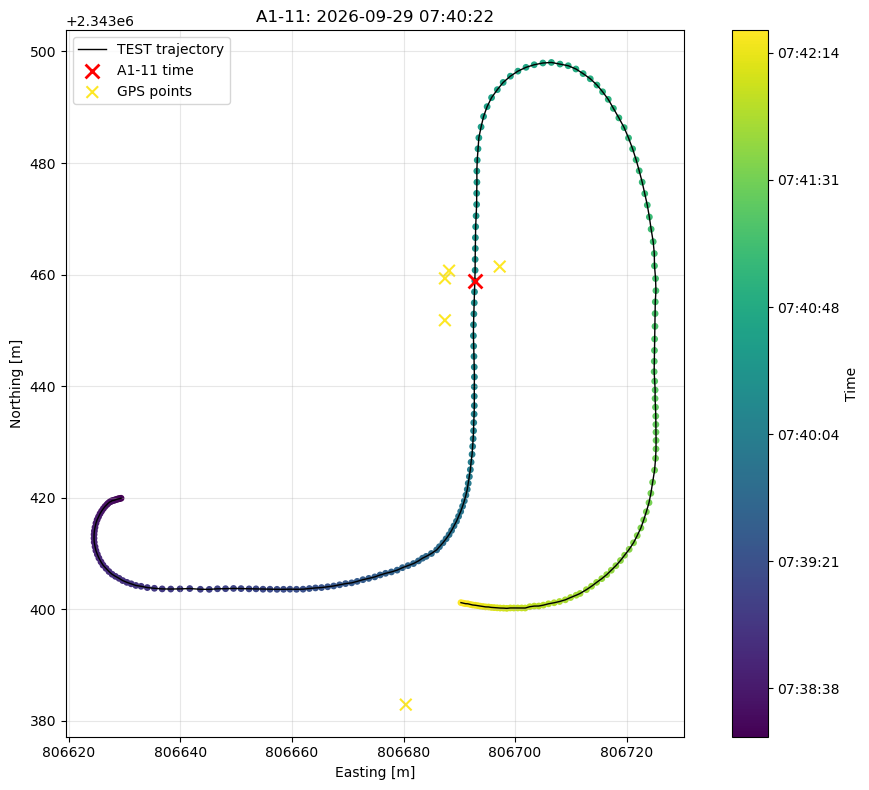

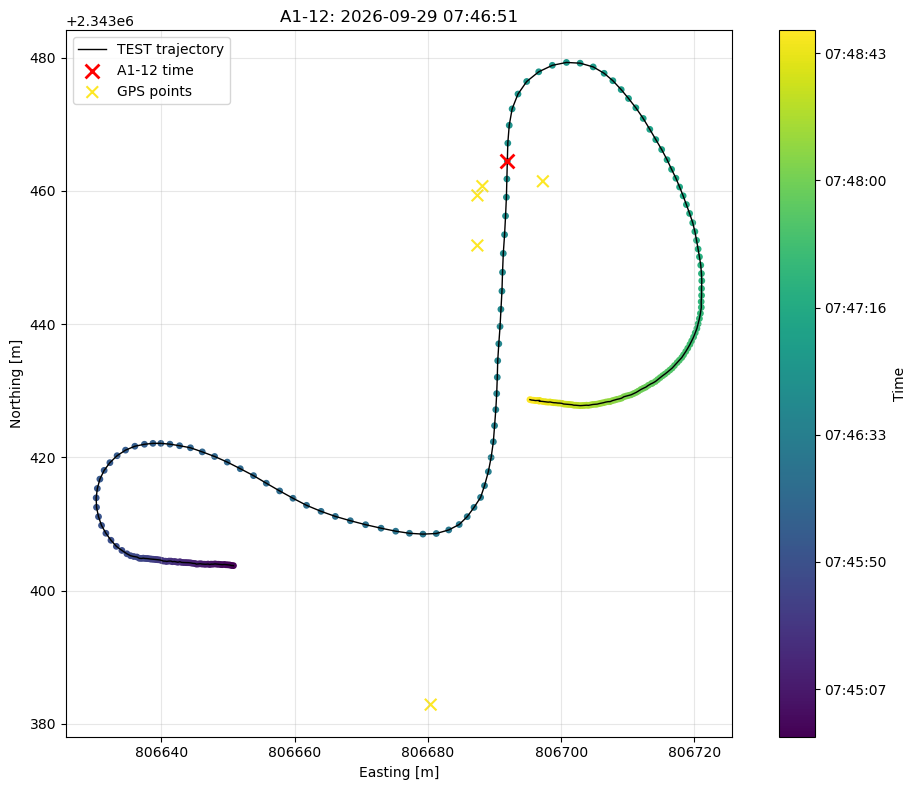

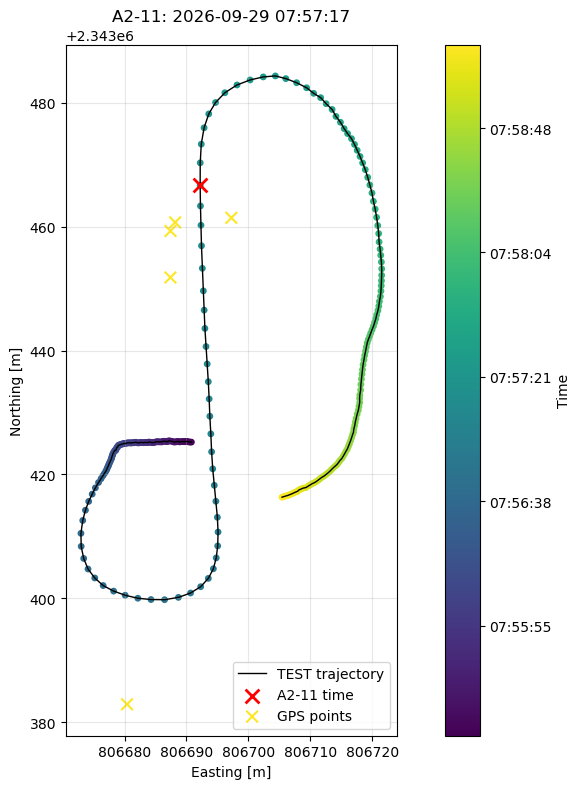

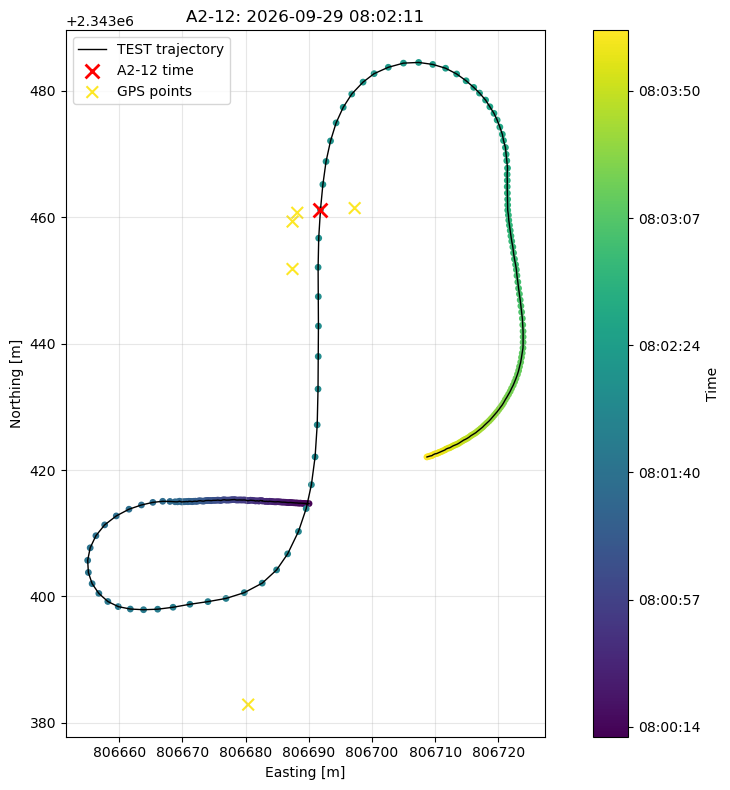

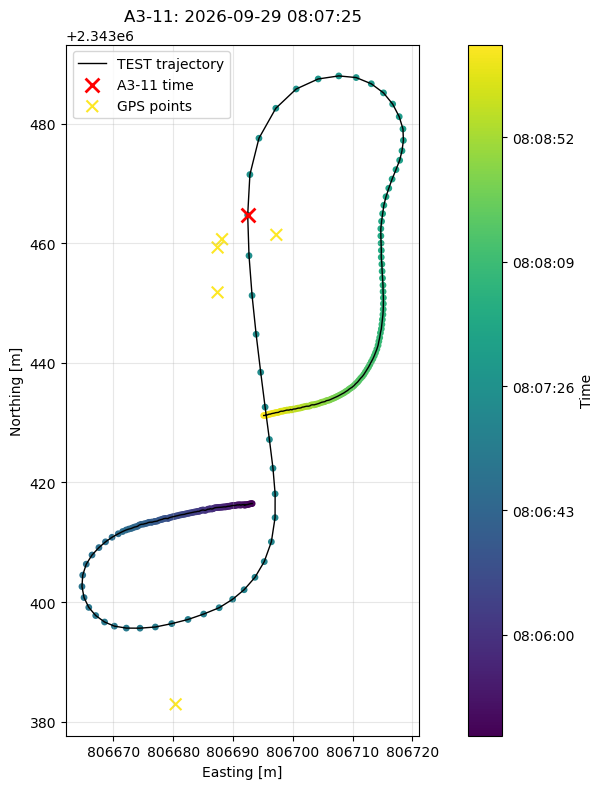

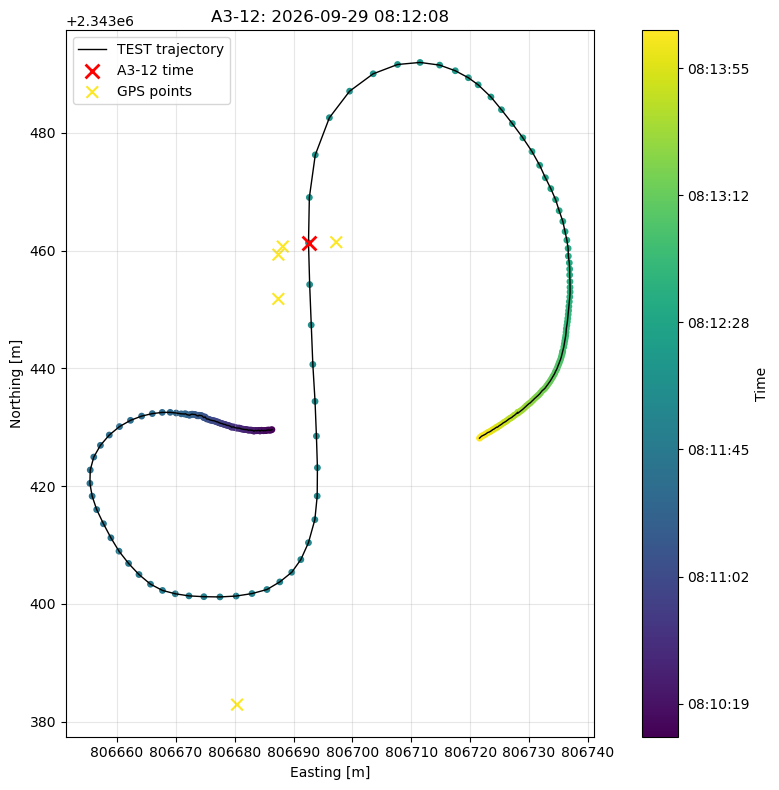

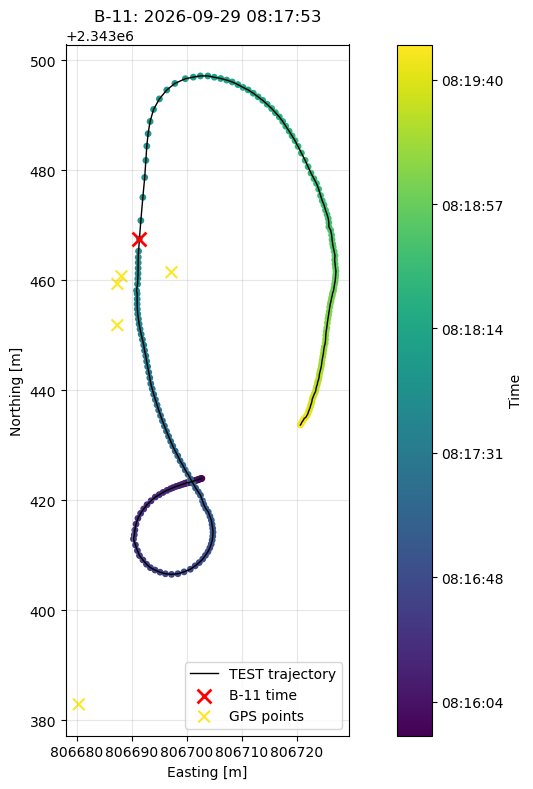

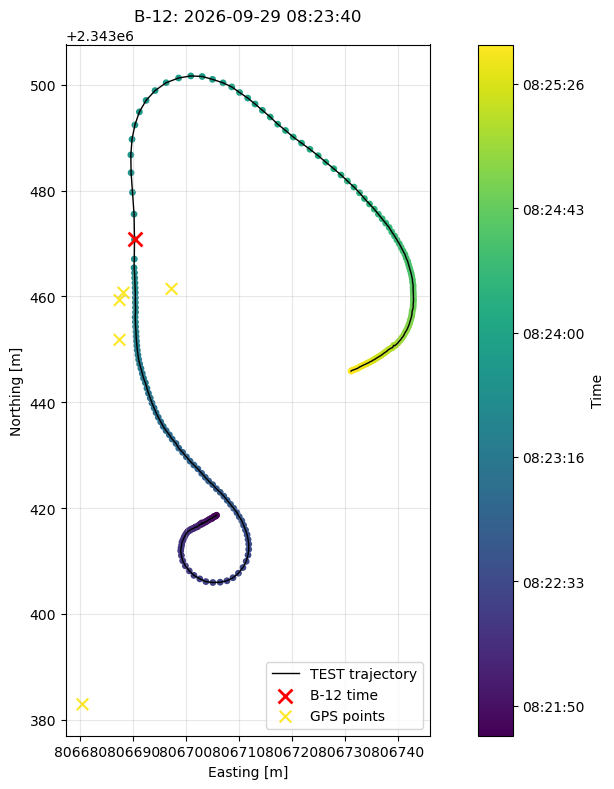

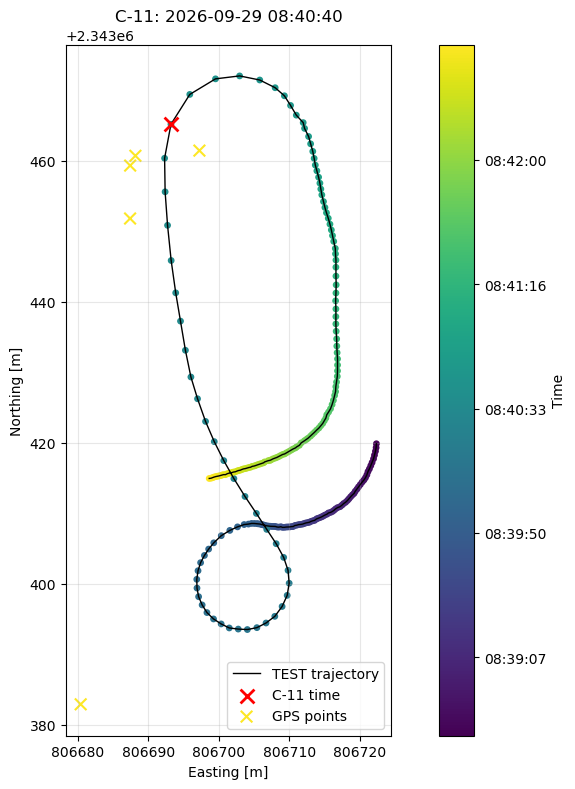

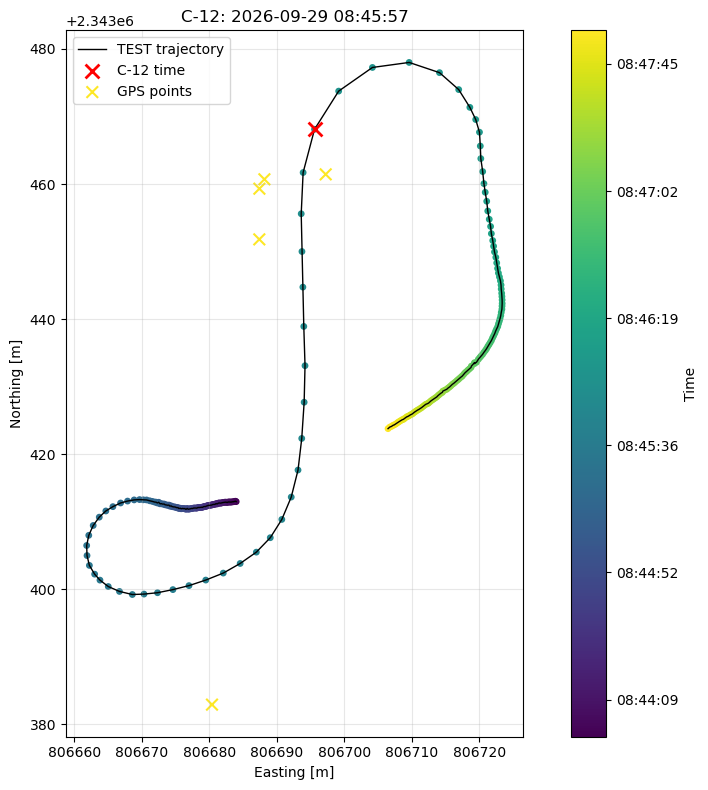

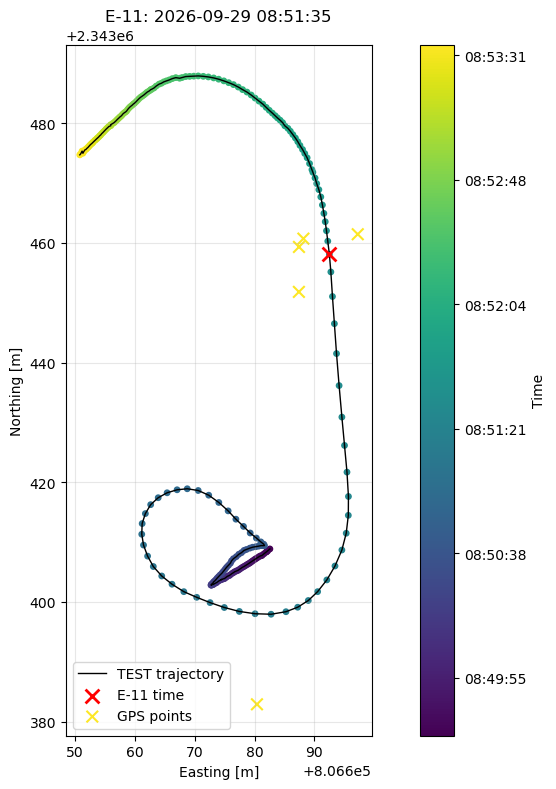

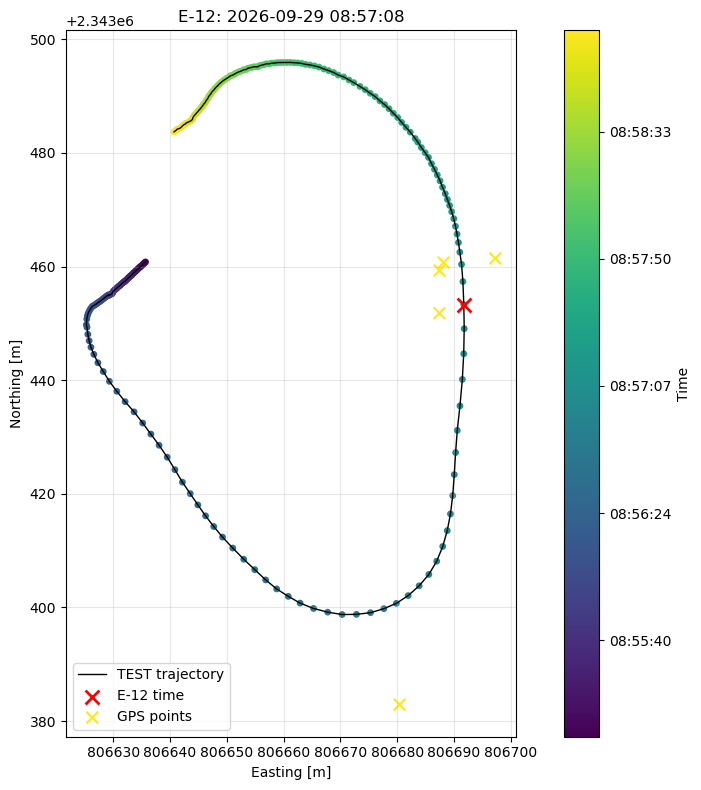

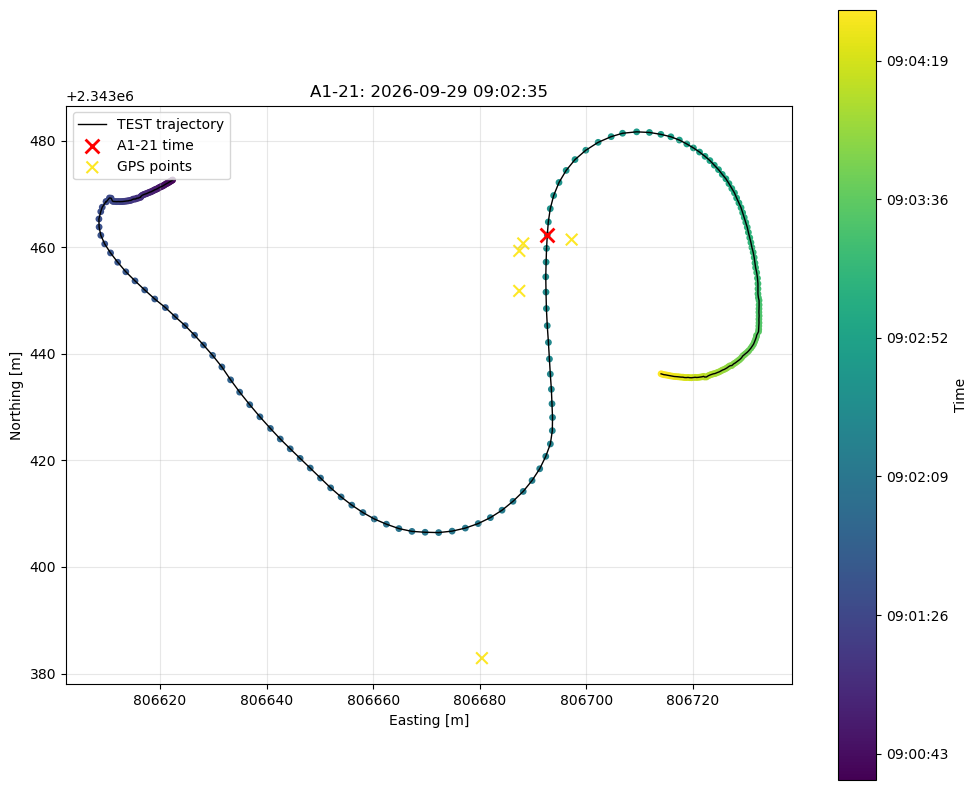

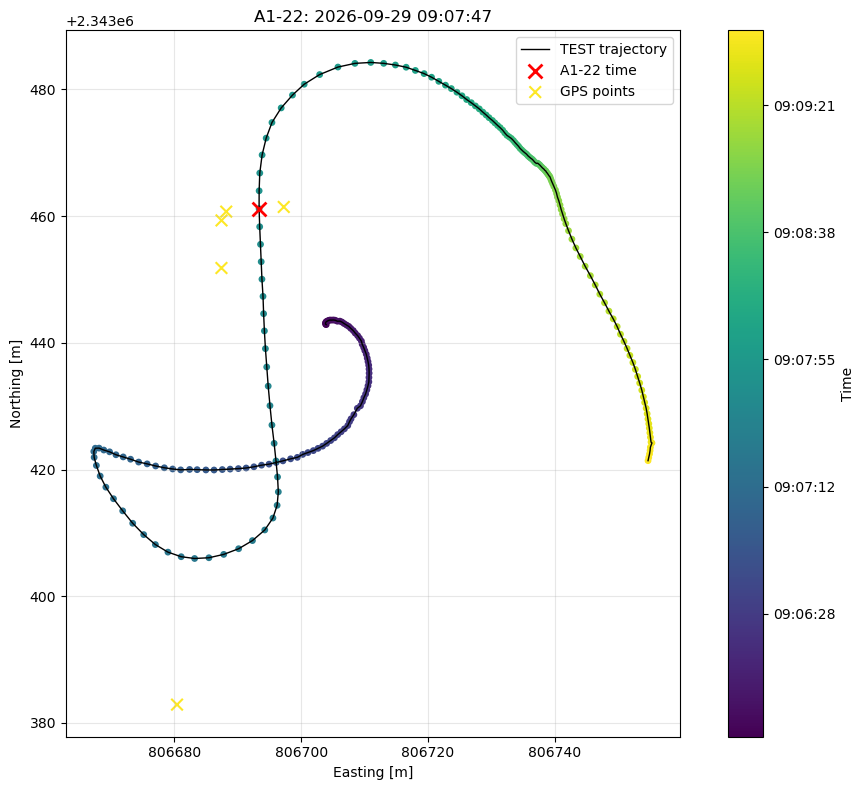

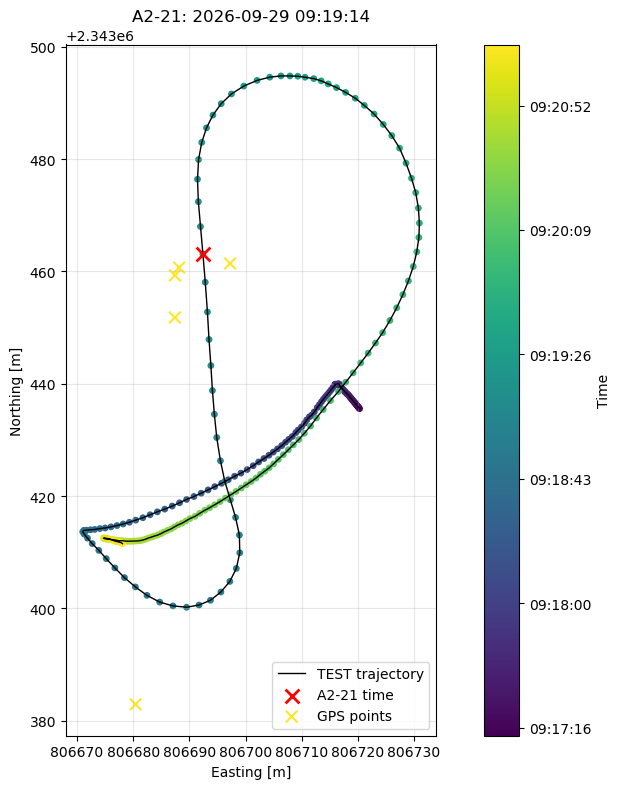

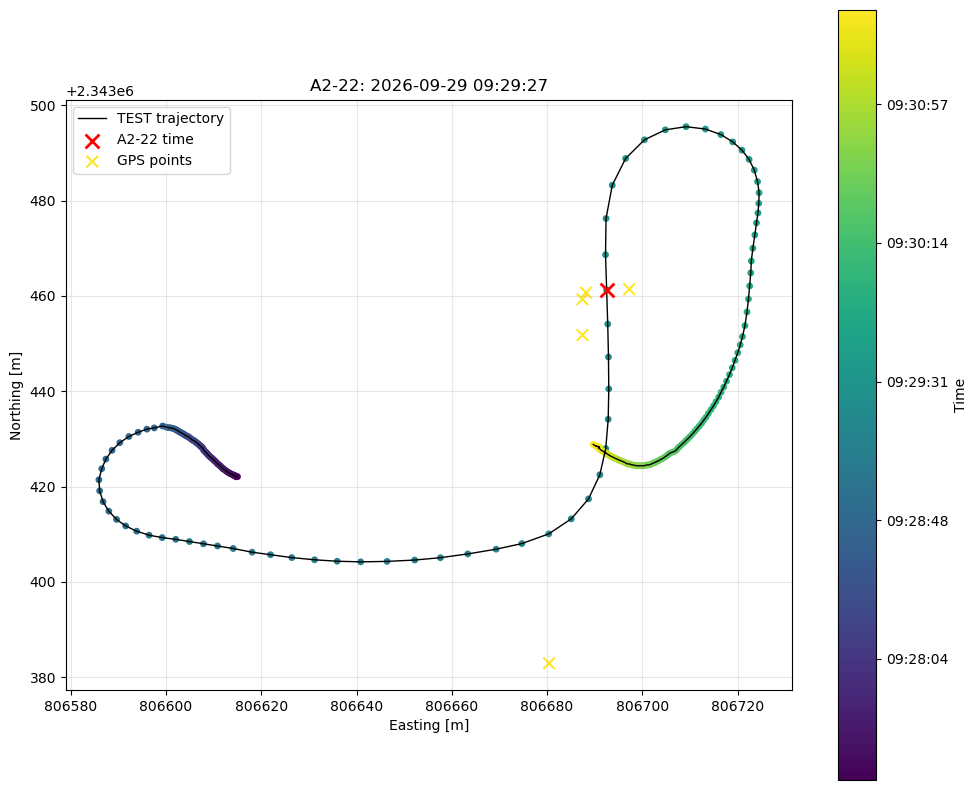

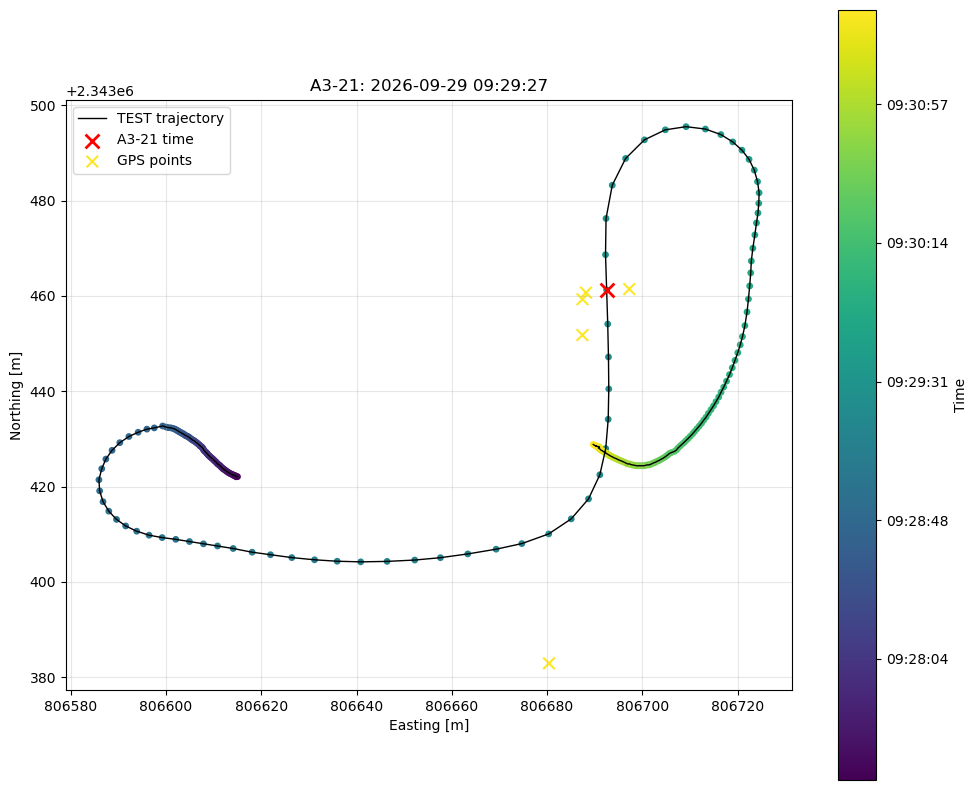

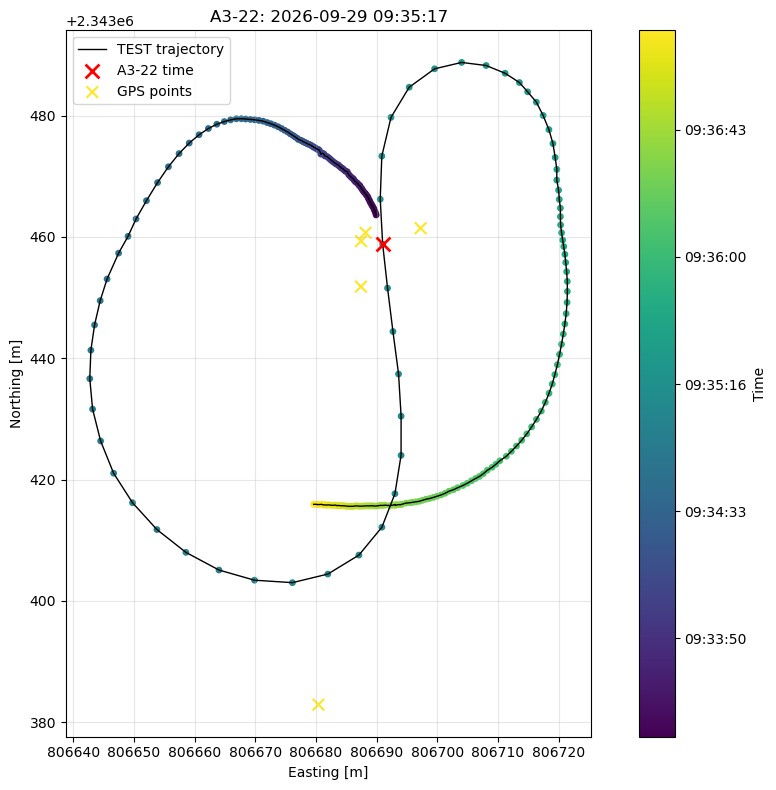

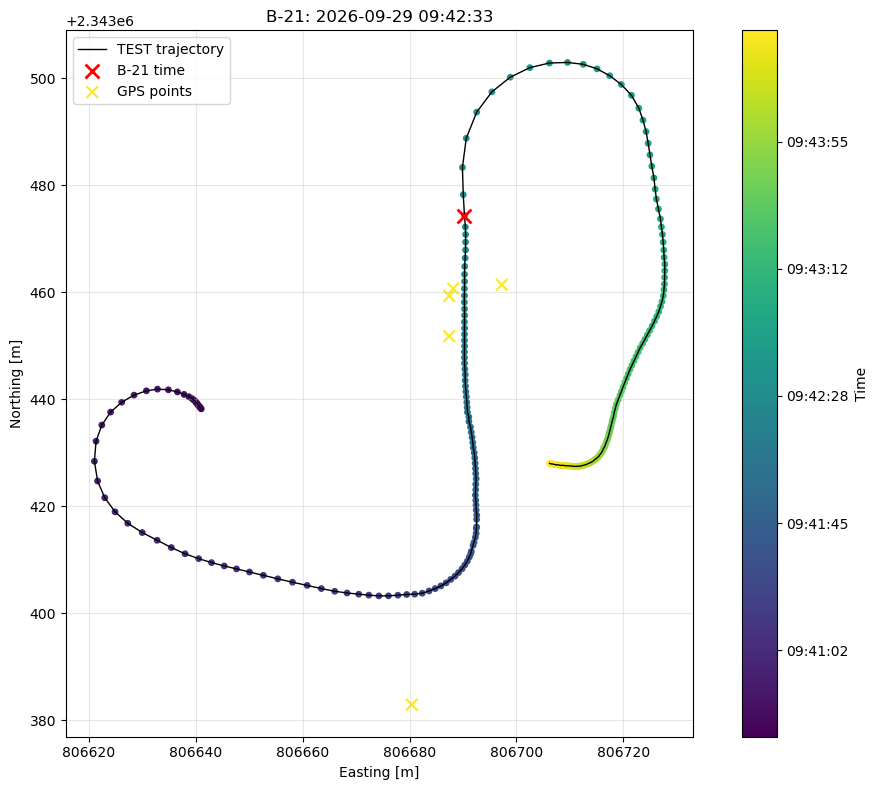

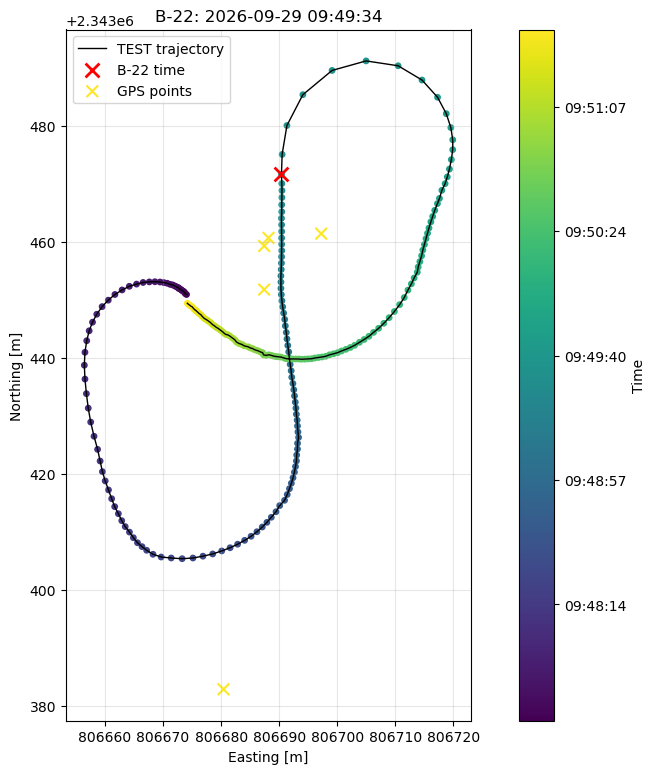

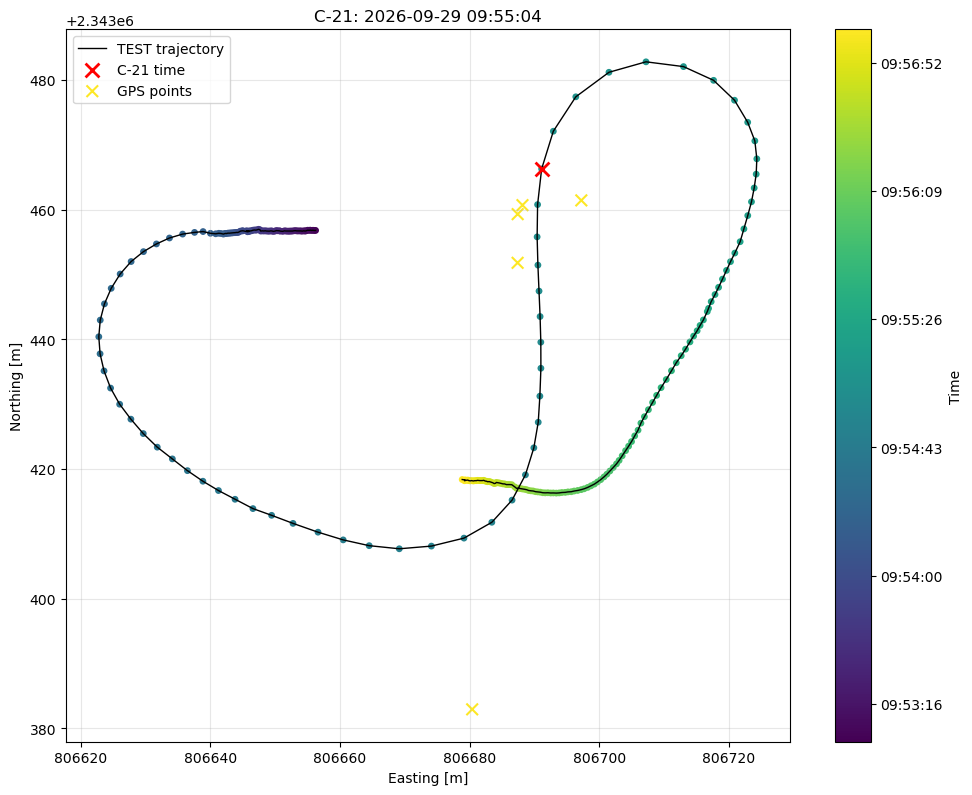

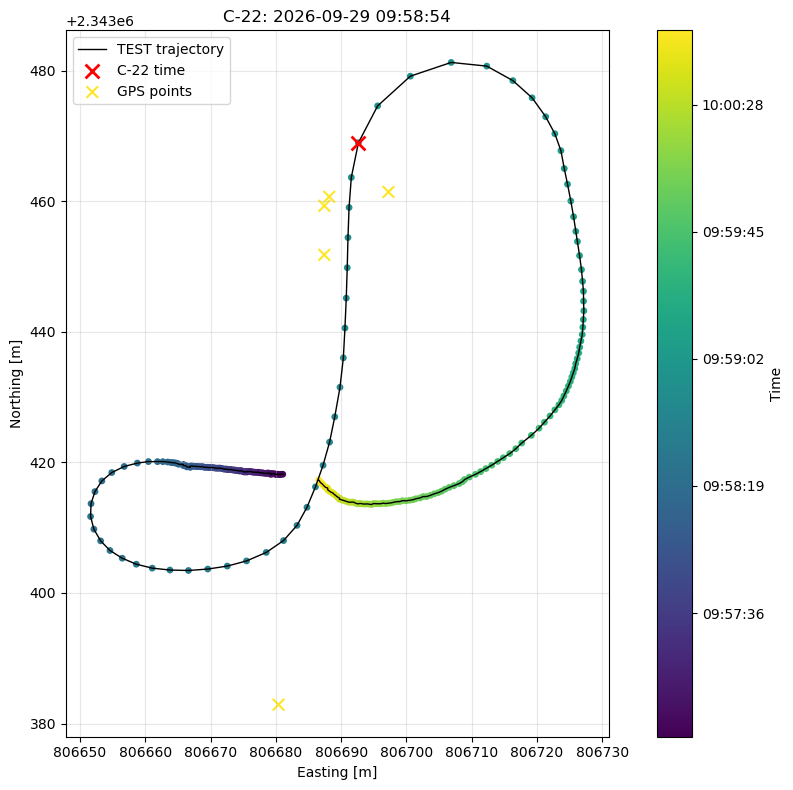

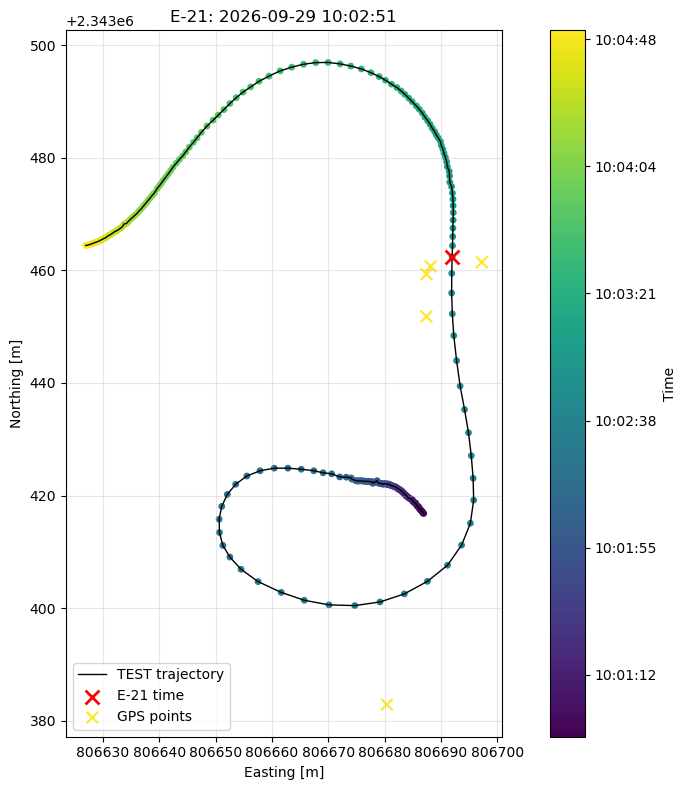

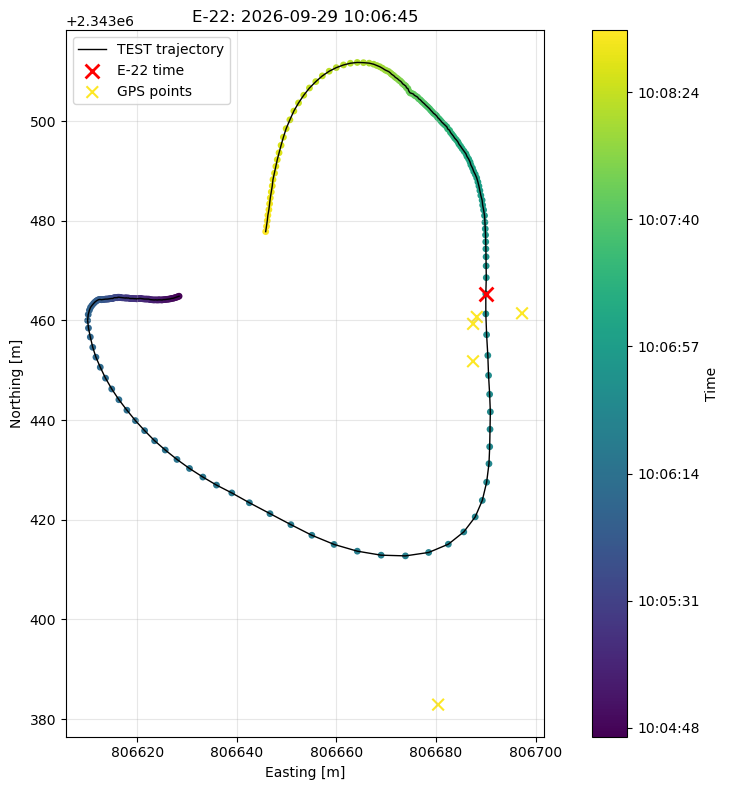

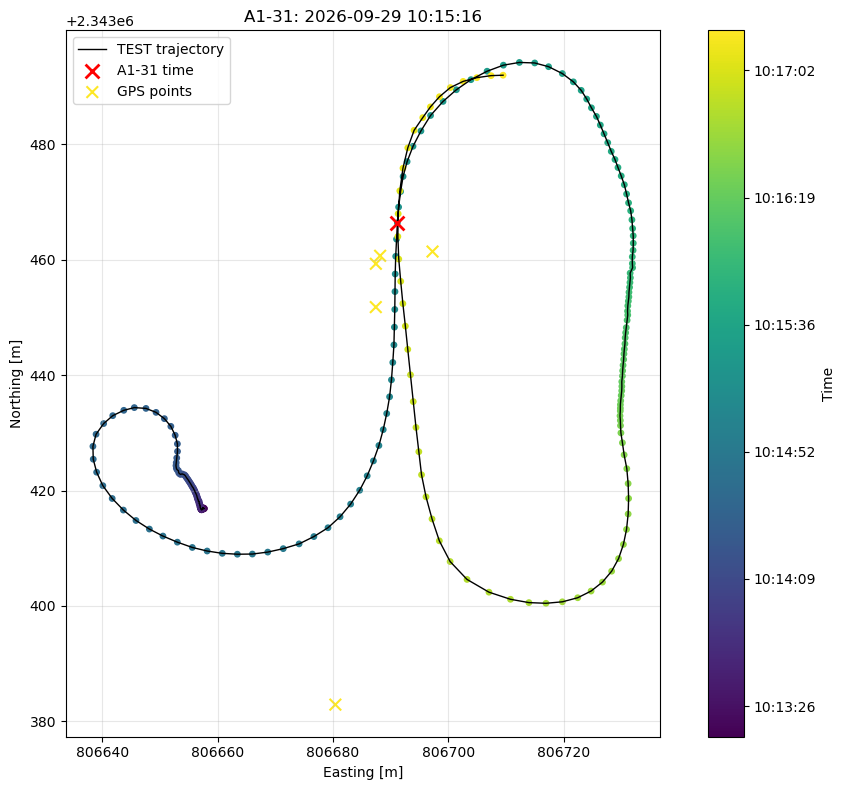

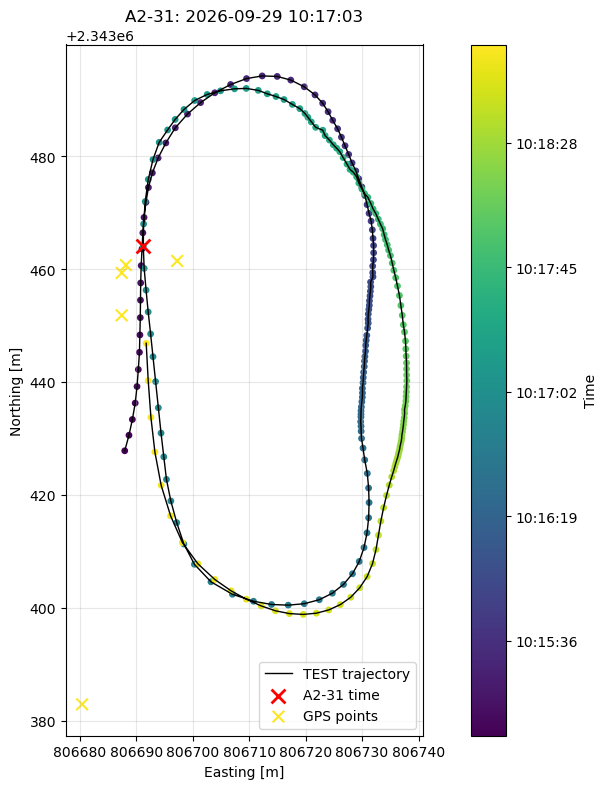

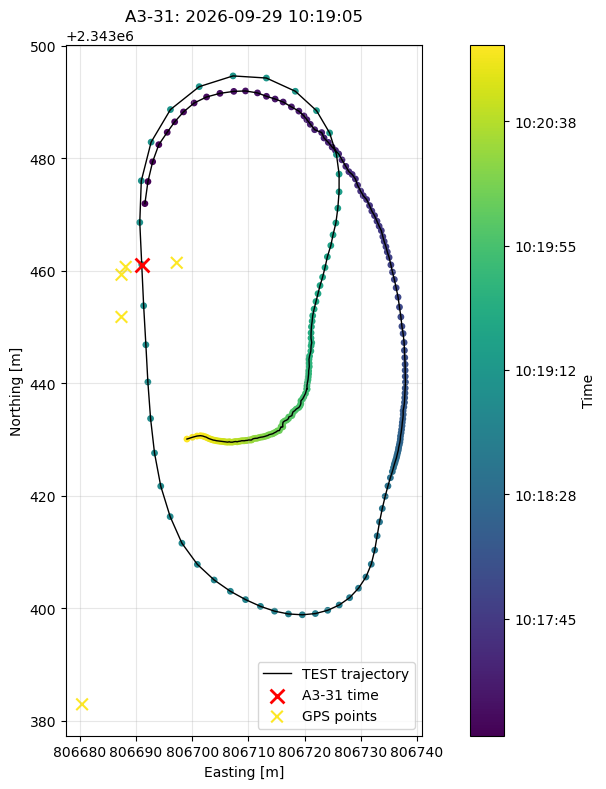

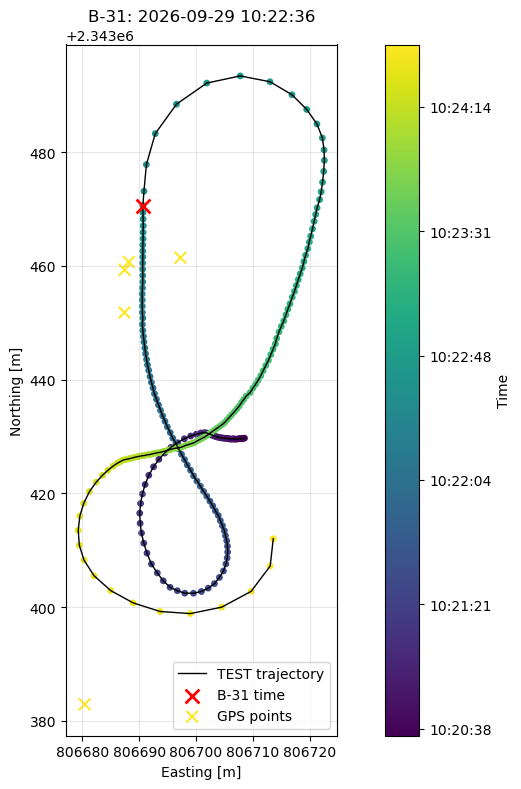

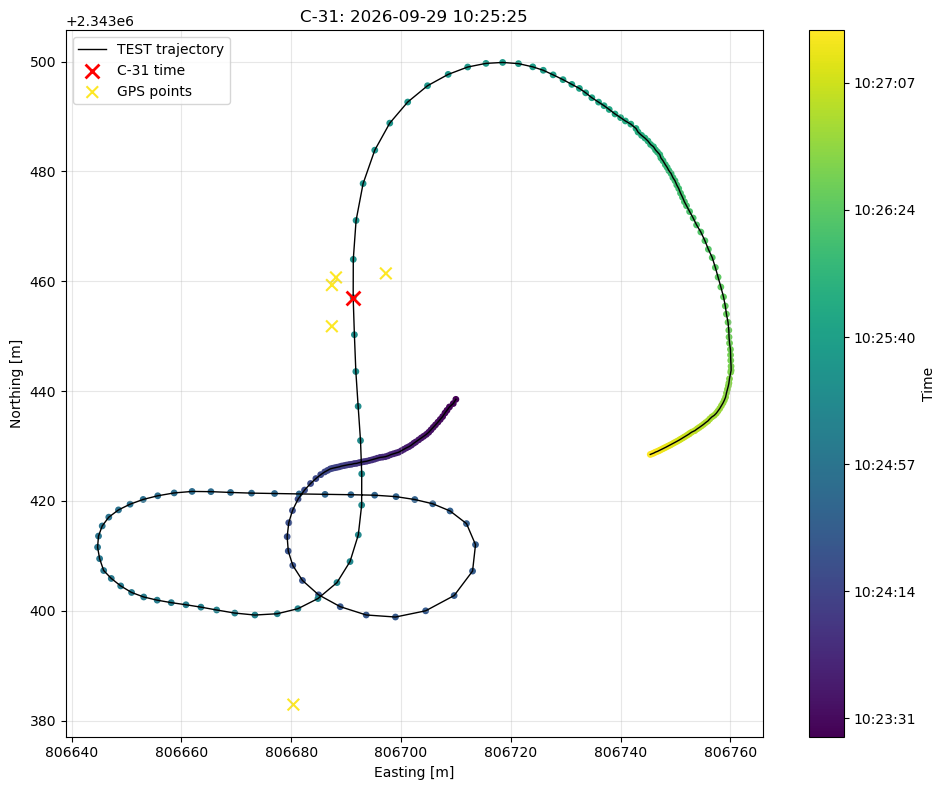

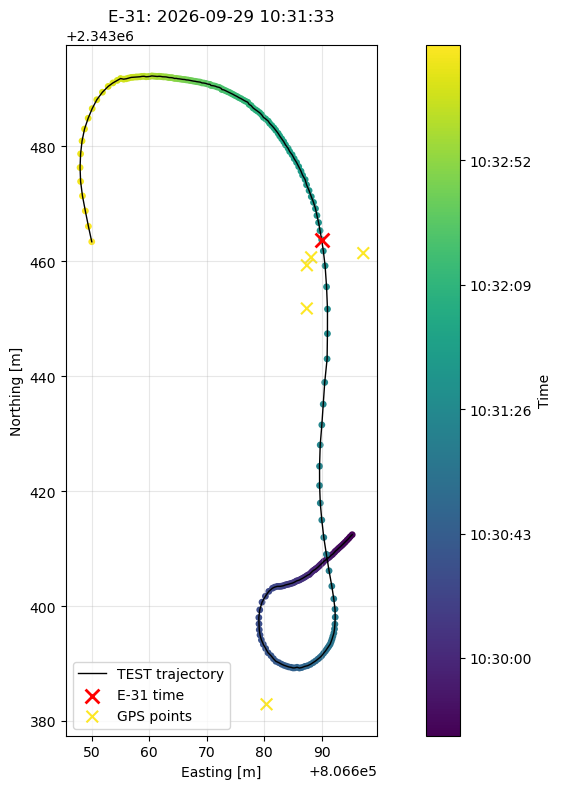

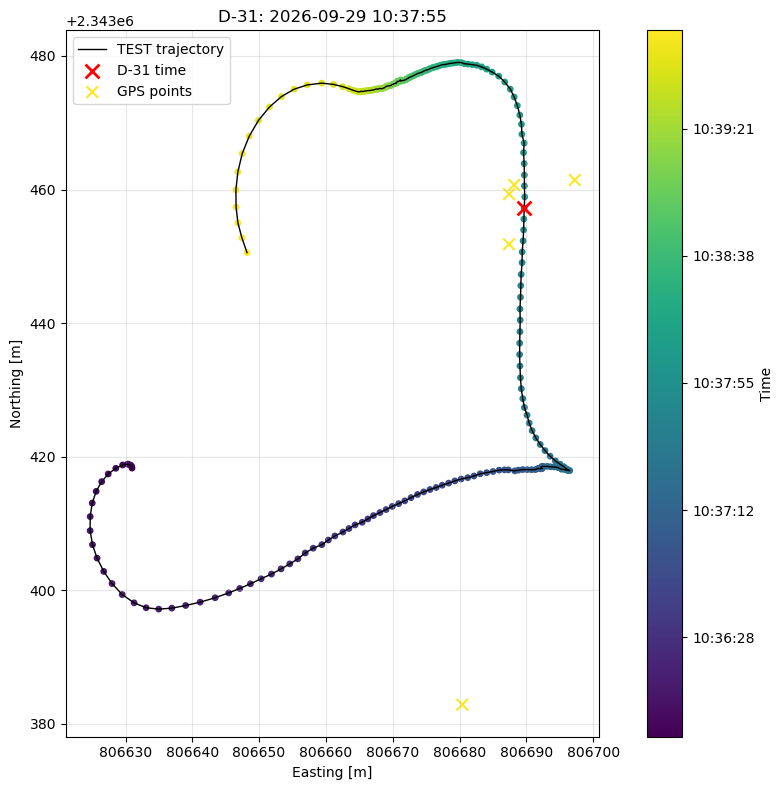

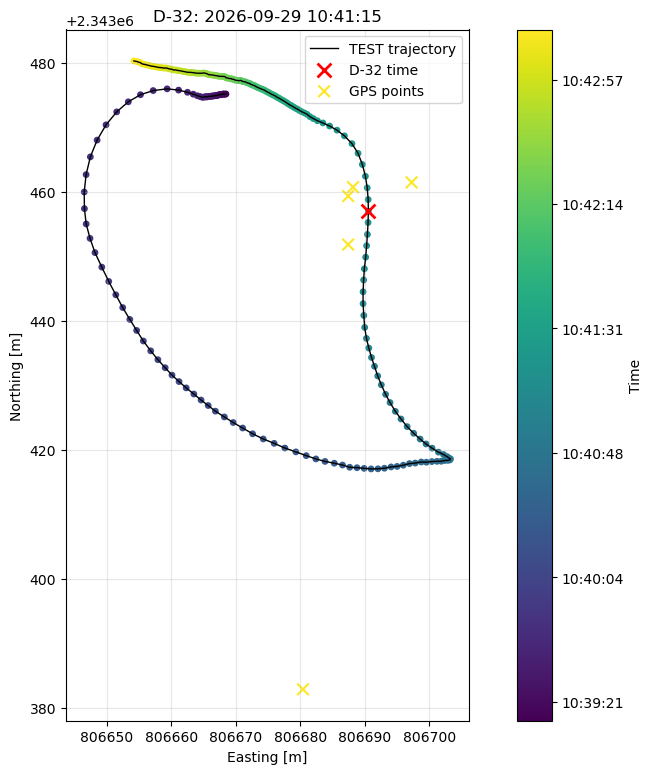

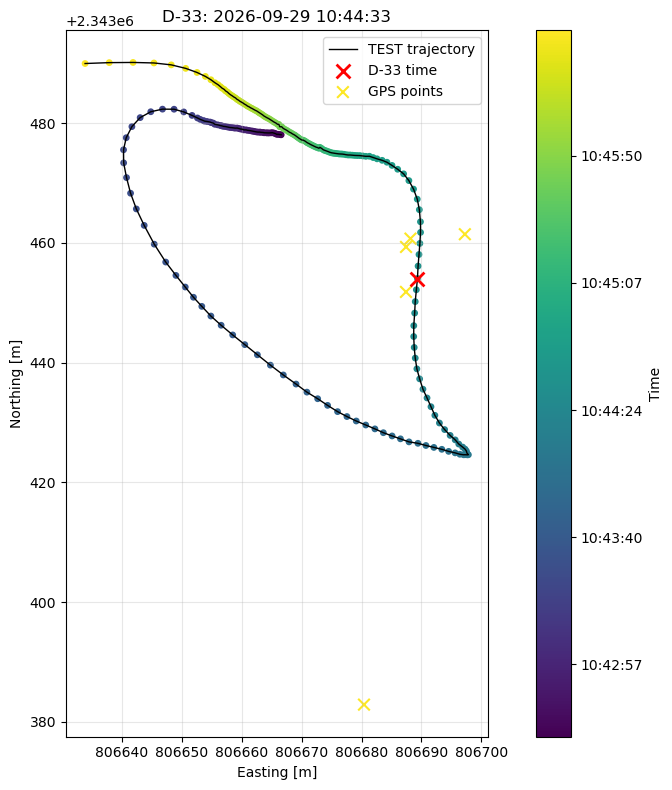

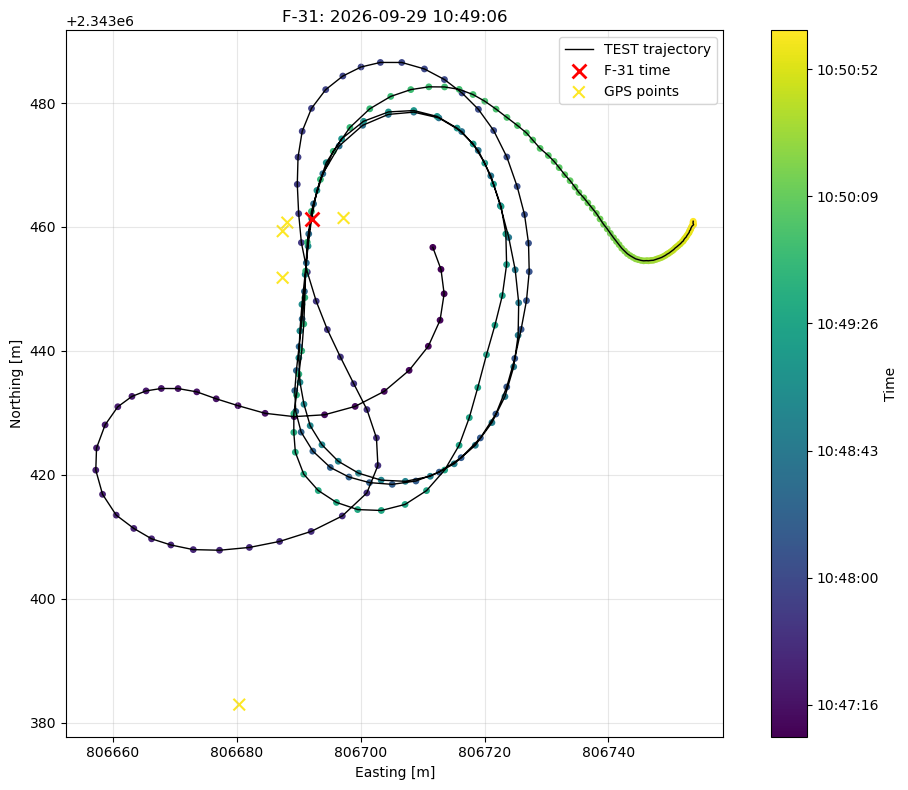

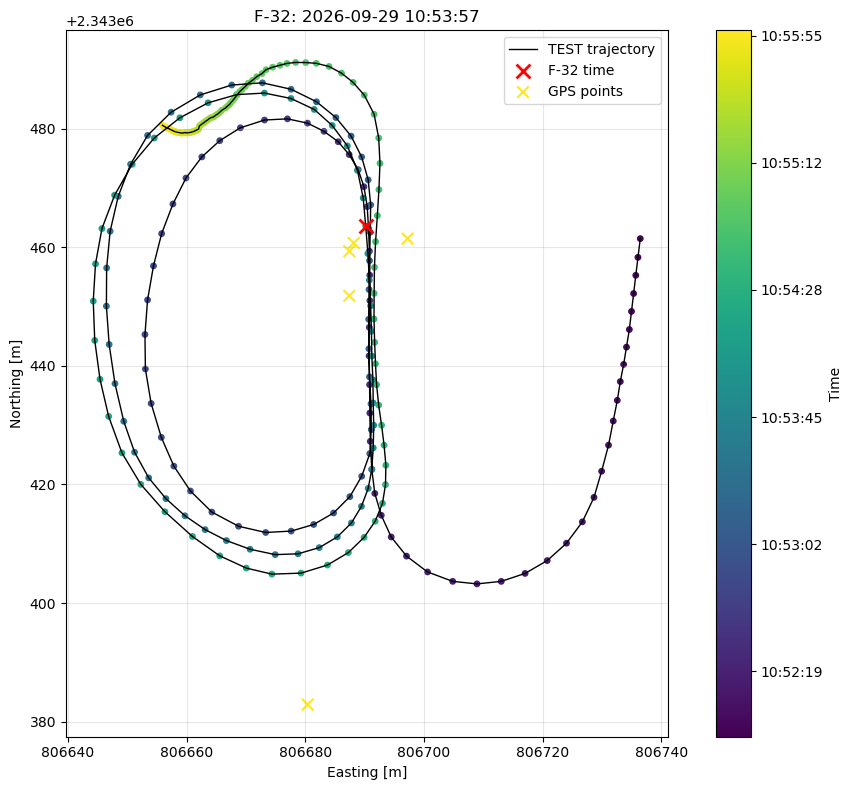

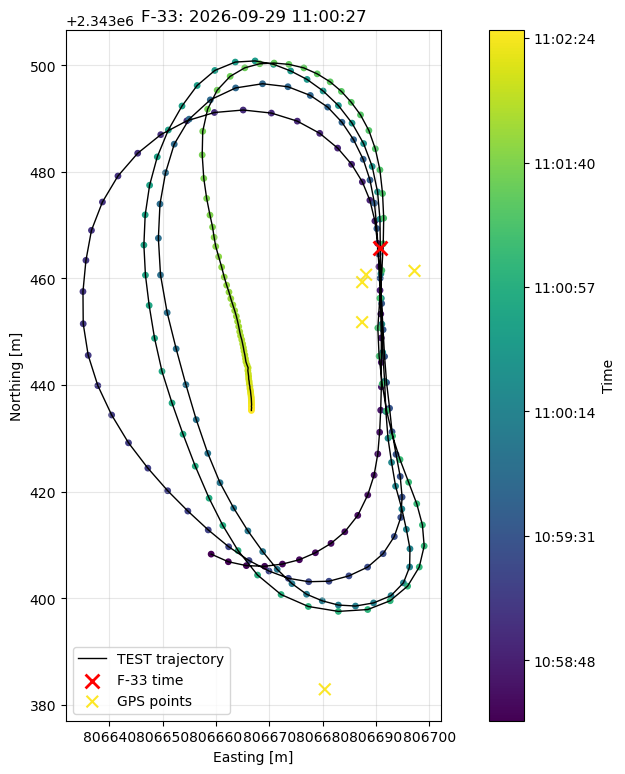

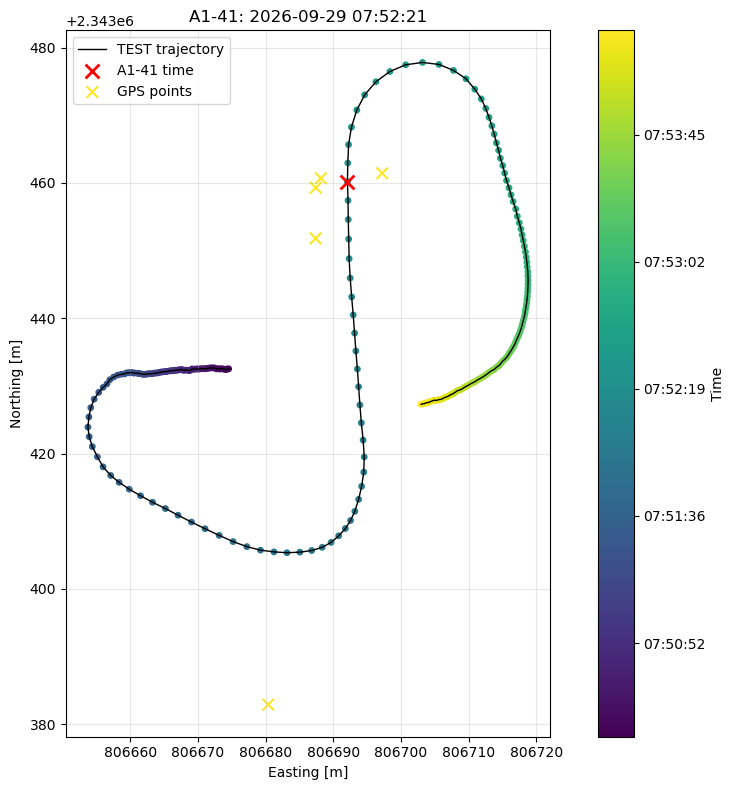

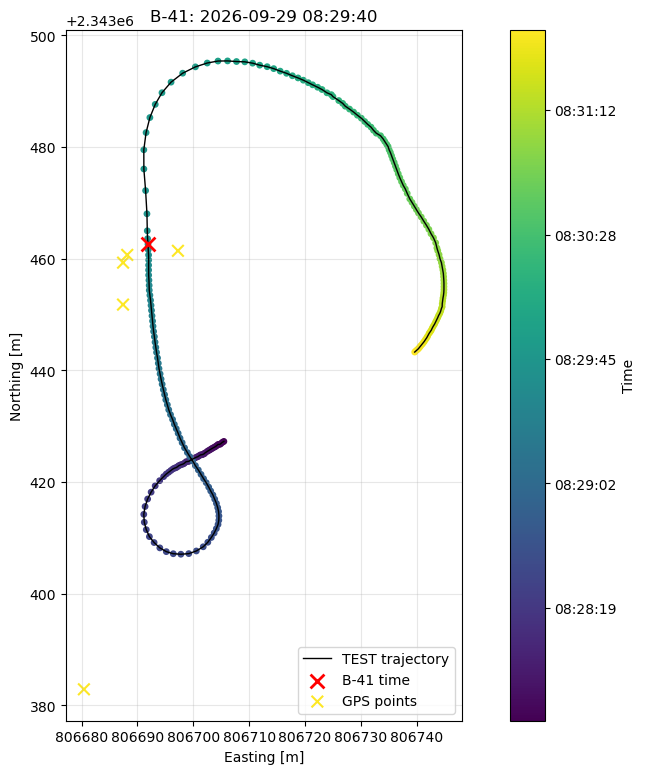

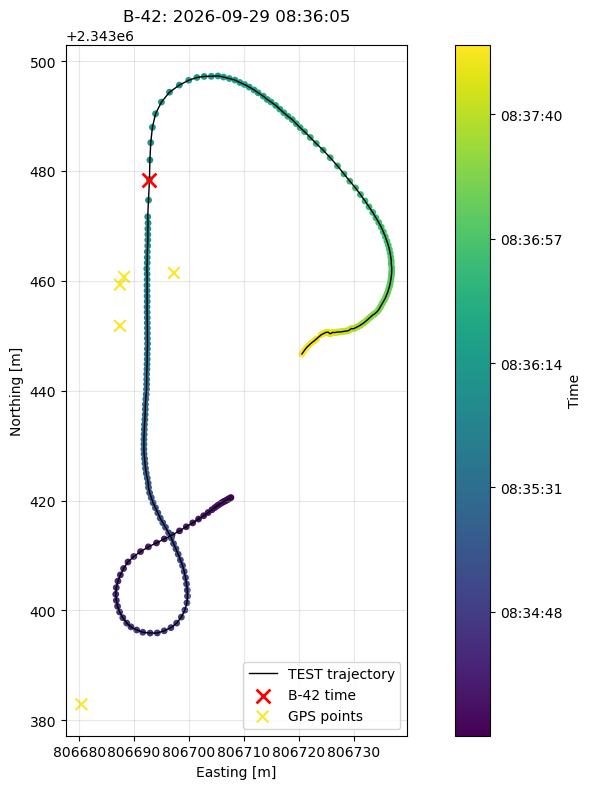

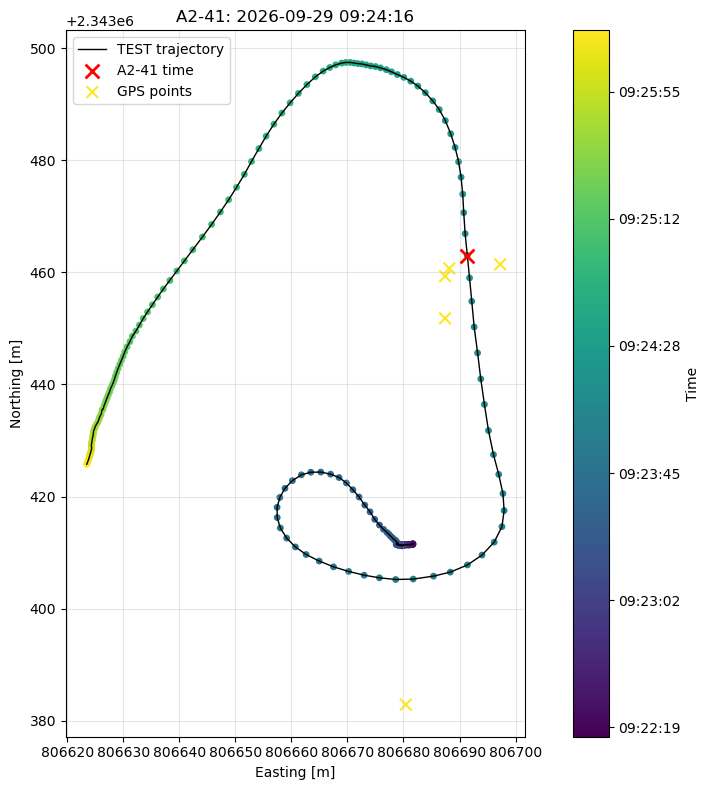

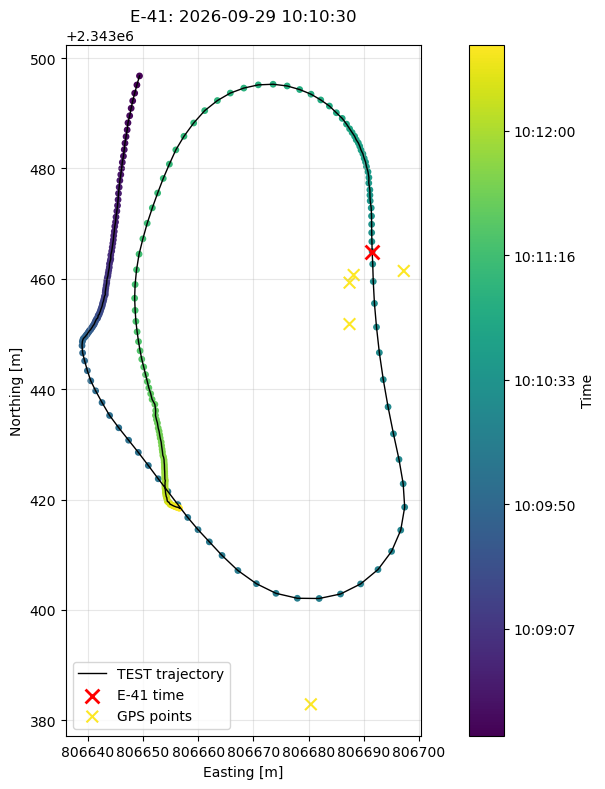

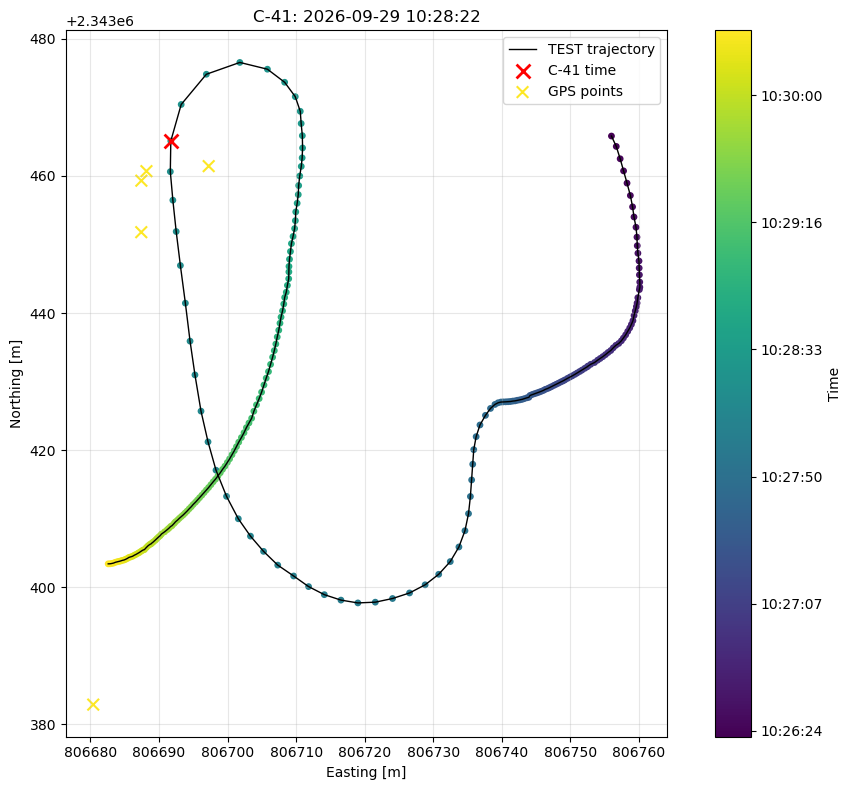

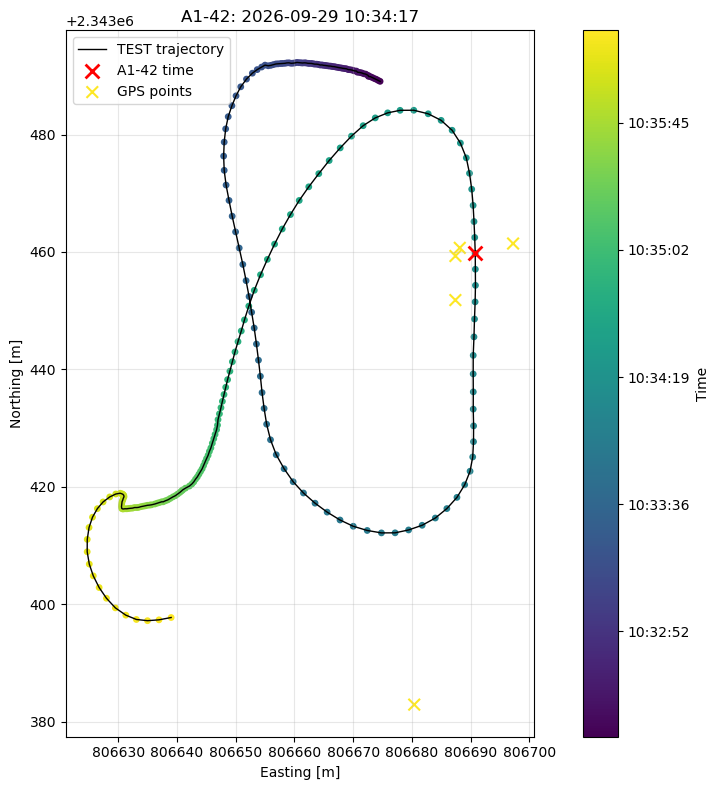

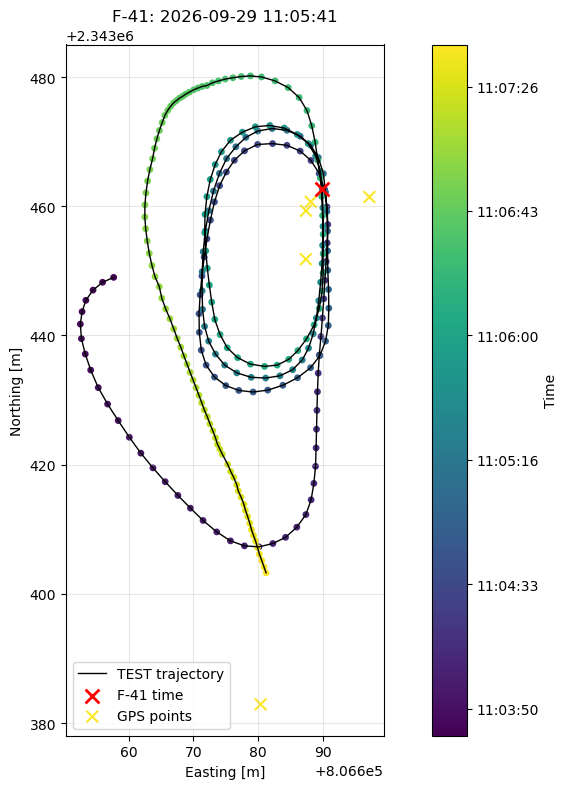

In [33]:
manoeuvre_date = "2026-09-29"

for manoeuvre_name, manoeuvre_time in manoeuvres.items():
    manoeuvre_datetime = pd.to_datetime(
        f"{manoeuvre_date} {manoeuvre_time}",
        format="%Y-%m-%d %H:%M:%S",
    )

    start_time = manoeuvre_datetime - pd.Timedelta(minutes=2)
    end_time = manoeuvre_datetime + pd.Timedelta(minutes=2)

    time_window = gps[
        gps["datetime"].between(start_time, end_time)
    ].copy()

    test_window = time_window[
        time_window["trajectory"] == "TEST"
    ].sort_values("datetime")

    if time_window.empty:
        print(f"No data found for {manoeuvre_name} at {manoeuvre_time}")
        continue

    time_values = mdates.date2num(time_window["datetime"])
    norm = mpl.colors.Normalize(
        time_values.min(),
        time_values.max(),
    )
    cmap = plt.colormaps["viridis"]

    fig, ax = plt.subplots(figsize=(10, 8))

    if not test_window.empty:
        ax.plot(
            test_window["easting"],
            test_window["northing"],
            color="black",
            linewidth=1,
            label="TEST trajectory",
        )

        ax.scatter(
            test_window["easting"],
            test_window["northing"],
            c=mdates.date2num(test_window["datetime"]),
            cmap=cmap,
            norm=norm,
            s=15,
        )

        # Interpolate the TEST position at the exact manoeuvre time.
        test_timestamps = test_window["datetime"].astype("int64")
        manoeuvre_timestamp = manoeuvre_datetime.value

        if (
            manoeuvre_timestamp >= test_timestamps.min()
            and manoeuvre_timestamp <= test_timestamps.max()
        ):
            manoeuvre_easting = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["easting"],
            )
            manoeuvre_northing = np.interp(
                manoeuvre_timestamp,
                test_timestamps,
                test_window["northing"],
            )

            ax.scatter(
                manoeuvre_easting,
                manoeuvre_northing,
                color="red",
                marker="x",
                s=100,
                linewidths=2,
                zorder=5,
                label=f"{manoeuvre_name} time",
            )

    # GPS measurements are discrete points and are not connected.
    ax.scatter(
        gps_points["easting"],
        gps_points["northing"],
        c=mdates.date2num(gps_points["datetime"]),
        cmap=cmap,
        norm=norm,
        marker="x",
        s=70,
        linewidths=1.5,
        label="GPS points",
        )

    ax.set_aspect("equal", adjustable="box")
    ax.set_xlabel("Easting [m]")
    ax.set_ylabel("Northing [m]")
    ax.set_title(
        f"{manoeuvre_name}: {manoeuvre_datetime:%Y-%m-%d %H:%M:%S}"
    )
    ax.legend()
    ax.grid(True, alpha=0.3)

    scalar_map = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
    scalar_map.set_array([])

    colorbar = fig.colorbar(scalar_map, ax=ax)
    colorbar.ax.yaxis.set_major_formatter(
        mdates.DateFormatter("%H:%M:%S")
    )
    colorbar.set_label("Time")

    plt.tight_layout()
    plt.show()

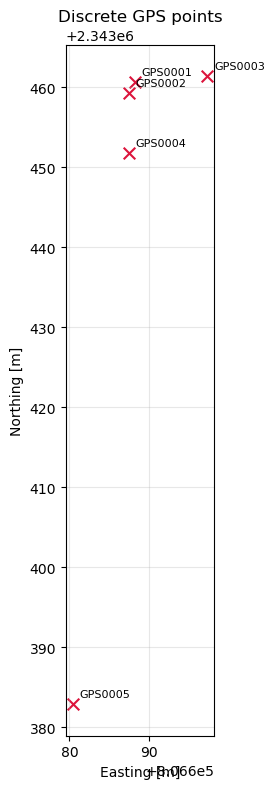

In [29]:
gps_points = gps[
    gps["trajectory"] == "GPS"
].sort_values("point_id")

fig, ax = plt.subplots(figsize=(10, 8))

ax.scatter(
    gps_points["easting"],
    gps_points["northing"],
    color="crimson",
    marker="x",
    s=70,
    linewidths=1.5,
)

for _, point in gps_points.iterrows():
    ax.annotate(
        point["point_id"],
        (point["easting"], point["northing"]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8,
    )

ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("Easting [m]")
ax.set_ylabel("Northing [m]")
ax.set_title("Discrete GPS points")
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()